# Fleet Profitability: Which cars actually paid off?

I've run a car rental business on Turo since April 2023, growing from one financed Hyundai Elantra to an 11-car fleet. Every time I buy a car I'm making a bet: will what it earns justify what I paid?

This notebook checks those bets with my own data: **1,469 completed trips from April 2023 to October 2026**.

> **Note on privacy:** this is my real business, so the underlying data isn't published and **every result is shown in relative terms** (growth multiples, indexes, and utilization) rather than dollars. The code runs on the real numbers; only the outputs are normalized.

**Questions**
1. How has the business grown year over year?
2. Which cars earn the most relative to what they cost?
3. Is it better to buy cheap cars that rent constantly, or expensive cars that earn more per day?
4. Was choosing an Elantra over another Civic the right call?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

DATA = Path("../data/processed")   # private; not included in this repo
FIGS = Path("../figures")
AS_OF = pd.Timestamp("2026-10-27")  # date of the latest Turo export

trips = pd.read_csv(DATA / "trips.csv", parse_dates=["trip_start", "trip_end"])
cars = pd.read_csv(DATA / "cars.csv")          # purchase price, status, segment per car
expenses = pd.read_csv(DATA / "monthly_expenses.csv")

completed = trips[trips.trip_status == "Completed"].copy()
print(f"{len(completed):,} completed trips on {completed.car.nunique()} cars, "
      f"{completed.trip_start.min():%b %Y} to {completed.trip_end.max():%b %Y}")

1,469 completed trips on 14 cars, Apr 2023 to Oct 2026


In [2]:
# Chart style: one recessive grid, no top/right spines, text in neutral ink.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "text.color": INK,
})
times = mtick.FuncFormatter(lambda v, _: f"{v:g}x")

## 1. Growth by year

Earnings are shown as a multiple of 2023, my first year.

In [3]:
yearly = completed.groupby(completed.trip_start.dt.year).agg(
    earnings=("total_earnings", "sum"), trips=("trip_id", "size"), cars_used=("car", "nunique"))
yearly["earnings_vs_2023"] = yearly.earnings / yearly.earnings.iloc[0]
yearly["trips_vs_2023"] = yearly.trips / yearly.trips.iloc[0]
yearly[["earnings_vs_2023", "trips_vs_2023", "cars_used"]].style.format(
    {"earnings_vs_2023": "{:.1f}x", "trips_vs_2023": "{:.1f}x"})

,earnings_vs_2023,trips_vs_2023,cars_used
trip_start,,,
2023,1.0x,1.0x,4
2024,2.5x,2.8x,7
2025,4.5x,4.5x,9
2026,3.7x,3.6x,13


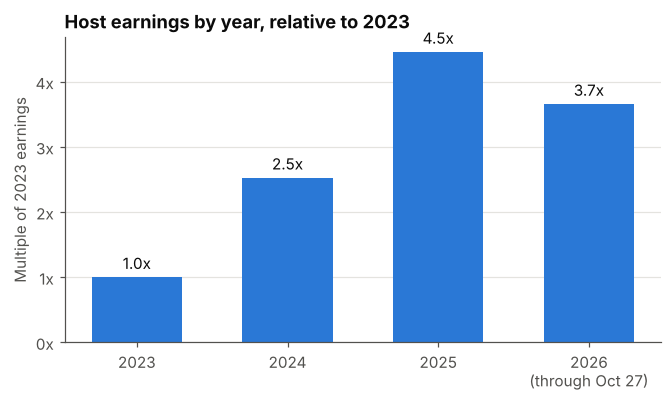

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [str(y) if y < AS_OF.year else f"{y}\n(through Oct 27)" for y in yearly.index]
bars = ax.bar(labels, yearly.earnings_vs_2023, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}x" for v in yearly.earnings_vs_2023], padding=3, color=INK)
ax.yaxis.set_major_formatter(times)
ax.grid(axis="x", visible=False)
ax.set_title("Host earnings by year, relative to 2023")
ax.set_ylabel("Multiple of 2023 earnings")
fig.savefig(FIGS / "01_growth_by_year.png")
plt.show()

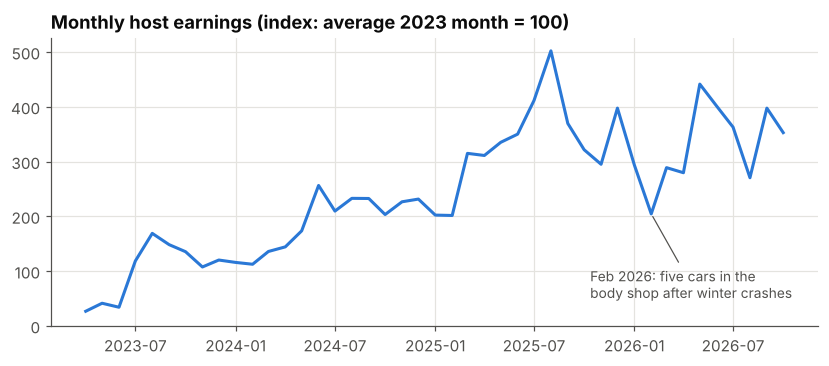

In [5]:
monthly = completed.set_index("trip_start").resample("MS").total_earnings.sum()
# Index: average month of 2023 = 100
monthly_idx = monthly / monthly[monthly.index.year == 2023].mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly_idx.index, monthly_idx.values, color=BLUE, lw=2)
feb = pd.Timestamp("2026-02-01")
ax.annotate("Feb 2026: five cars in the\nbody shop after winter crashes", xy=(feb, monthly_idx[feb]),
            xytext=(-40, -55), textcoords="offset points", color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_ylim(0, None)
ax.set_title("Monthly host earnings (index: average 2023 month = 100)")
fig.savefig(FIGS / "02_monthly_index.png")
plt.show()

## 2. Profitability per car

**How I measure it**
- **Earnings** are Turo's *Total earnings*, which is what I'm paid after Turo's cut and protection plan.
- **Operating costs** come from my expense tracker: maintenance, parking tickets, washes, gas, registrations, and Uber rides back from deliveries. I don't track them per car, so I spread them evenly over every rental day in the last 12 months.
- **Net per month** = (earnings - allocated costs) / months the car has been listed.
- **Monthly return** = net per month / purchase price. This puts a $24K Elantra and a $78K Navigator on the same scale.
- **Return index** = a car's monthly return divided by the whole fleet's. 1.0 is average; 1.5 means the car earns back its price 50% faster than average.

All my financing is at 0% APR, so there's no interest to subtract.

In [6]:
last_12 = completed[(completed.trip_start >= AS_OF - pd.DateOffset(months=12)) & (completed.trip_start < AS_OF)]
cost_per_rental_day = expenses.drop(columns="month").sum().sum() / last_12.trip_days.sum()

per_car = (completed.groupby("car")
           .agg(trips=("trip_id", "size"), rental_days=("trip_days", "sum"),
                earnings=("total_earnings", "sum"), first_trip=("trip_start", "min"),
                last_trip=("trip_end", "max"))
           .reset_index().merge(cars, on="car"))

# A car is "in service" from its first trip until today, or until its last trip if it's gone.
per_car["in_service_end"] = per_car.last_trip.where(per_car.status != "Active", AS_OF)
per_car["months_listed"] = (per_car.in_service_end - per_car.first_trip).dt.days / 30.44
per_car["utilization"] = per_car.rental_days / (per_car.months_listed * 30.44)
per_car["earnings_per_day"] = per_car.earnings / per_car.rental_days
per_car["net_per_month"] = (per_car.earnings - per_car.rental_days * cost_per_rental_day) / per_car.months_listed
per_car["monthly_return"] = per_car.net_per_month / per_car.purchase_price
per_car["tier"] = np.where(per_car.purchase_price < 35000, "Economy (under $35K)", "Premium ($49K+)")

# Normalize so no dollar figures appear in the output.
fleet_return = per_car.net_per_month.sum() / per_car.purchase_price.sum()
baseline_day_rate = per_car.set_index("car").loc["Elantra 2023", "earnings_per_day"]
per_car["return_index"] = per_car.monthly_return / fleet_return
per_car["day_rate_index"] = per_car.earnings_per_day / baseline_day_rate
per_car = per_car.sort_values("return_index", ascending=False)

per_car[["car", "tier", "status", "months_listed", "utilization", "day_rate_index", "return_index"]].style.format({
    "months_listed": "{:.1f}", "utilization": "{:.0%}", "day_rate_index": "{:.1f}x",
    "return_index": "{:.2f}"}).hide(axis="index")

car,tier,status,months_listed,utilization,day_rate_index,return_index
Elantra 2024 (black),Economy (under $35K),Active,23.2,78%,1.0x,1.48
Elantra 2024 (white),Economy (under $35K),Totaled,21.9,74%,1.0x,1.47
Trax 2026 #2,Economy (under $35K),Active,2.7,77%,1.0x,1.45
Trax 2026 #1,Economy (under $35K),Active,2.8,76%,1.0x,1.38
Elantra 2023,Economy (under $35K),Active,42.7,69%,1.0x,1.32
Sportage 2023,Economy (under $35K),Active,39.7,72%,1.1x,1.26
Civic 2022,Economy (under $35K),Retired,13.7,69%,1.0x,1.18
Corvette 2026,Premium ($49K+),Active,6.1,25%,5.4x,1.11
Tahoe 2026,Premium ($49K+),Active,2.8,68%,1.6x,0.95
Mercedes CLA 2025,Premium ($49K+),Active,14.6,43%,2.0x,0.92


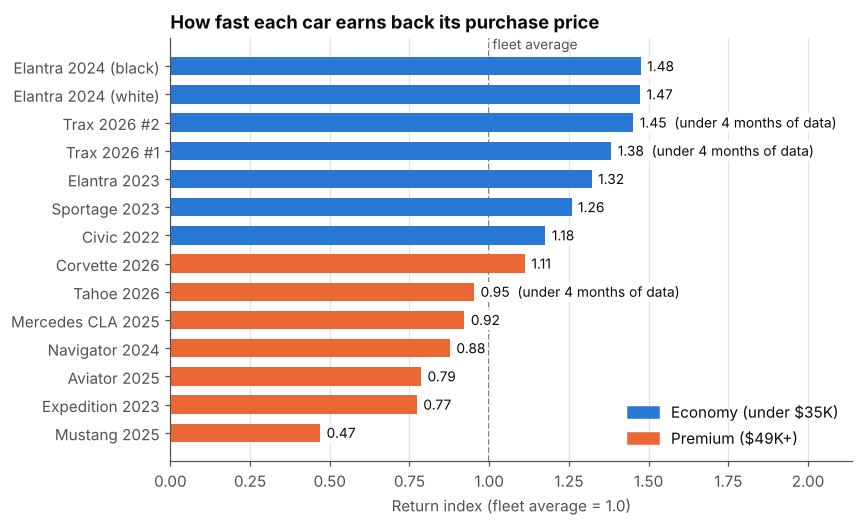

In [7]:
d = per_car.sort_values("return_index")
colors = [BLUE if t.startswith("Economy") else ORANGE for t in d.tier]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(d.car, d.return_index, color=colors, height=0.65)
ax.axvline(1, color=MUTED, lw=1, ls="--", zorder=0)
ax.text(1.01, len(d) - 0.4, "fleet average", color=MUTED, fontsize=9)
for y, (v, m) in enumerate(zip(d.return_index, d.months_listed)):
    note = "  (under 4 months of data)" if m < 4 else ""
    ax.text(v + 0.02, y, f"{v:.2f}{note}", va="center", fontsize=9, color=INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, d.return_index.max() * 1.45)
ax.set_title("How fast each car earns back its purchase price")
ax.set_xlabel("Return index (fleet average = 1.0)")
ax.legend(handles=[Patch(color=BLUE, label="Economy (under $35K)"), Patch(color=ORANGE, label="Premium ($49K+)")],
          frameon=False, loc="lower right")
fig.savefig(FIGS / "03_return_index_by_car.png")
plt.show()

## 3. Cheap and busy vs. expensive and occasional

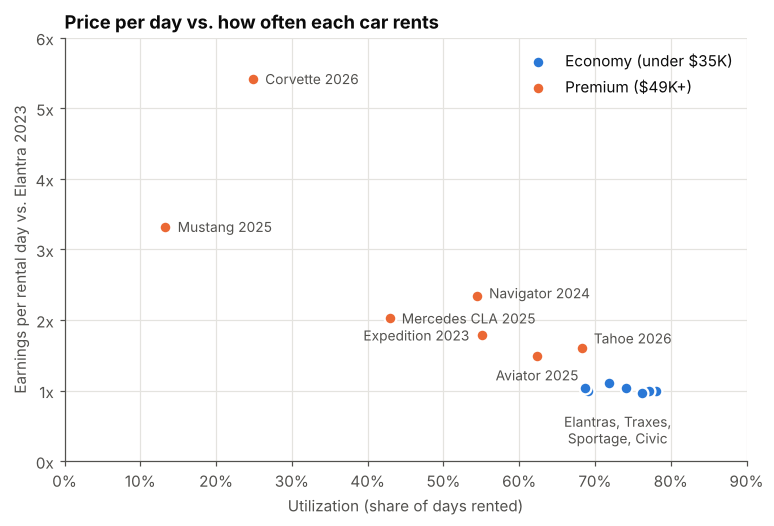

,cars,avg_utilization,day_rate_index,return_index
tier,,,,
Economy (under $35K),7,72%,1.0x,1.36
Premium ($49K+),7,46%,2.1x,0.85


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for tier, color in [("Economy (under $35K)", BLUE), ("Premium ($49K+)", ORANGE)]:
    s = per_car[per_car.tier == tier]
    ax.scatter(s.utilization, s.day_rate_index, s=60, color=color, label=tier,
               edgecolor="white", linewidth=1.5, zorder=3)
# Label placement tuned by hand so names don't collide in the crowded lower-right corner.
offsets = {"Tahoe 2026": (8, 6, "left"), "Aviator 2025": (0, -13, "center"),
           "Expedition 2023": (-8, 0, "right"), "Navigator 2024": (8, 2, "left")}
for _, r in per_car[per_car.tier.str.startswith("Premium")].iterrows():
    dx, dy, ha = offsets.get(r.car, (8, 0, "left"))
    ax.annotate(r.car, (r.utilization, r.day_rate_index), xytext=(dx, dy), ha=ha,
                textcoords="offset points", va="center", fontsize=9, color=MUTED)
ax.annotate("Elantras, Traxes,\nSportage, Civic", (0.73, 0.98), xytext=(0, -14),
            textcoords="offset points", ha="center", va="top", fontsize=9, color=MUTED)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(times)
ax.set_xlim(0, 0.9); ax.set_ylim(0, 6)
ax.set_xlabel("Utilization (share of days rented)")
ax.set_ylabel("Earnings per rental day vs. Elantra 2023")
ax.set_title("Price per day vs. how often each car rents")
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIGS / "04_day_rate_vs_utilization.png")
plt.show()

summary = per_car.groupby("tier").apply(lambda g: pd.Series({
    "cars": len(g), "avg_utilization": g.rental_days.sum() / (g.months_listed * 30.44).sum(),
    "day_rate_index": (g.earnings.sum() / g.rental_days.sum()) / baseline_day_rate,
    "return_index": (g.net_per_month.sum() / g.purchase_price.sum()) / fleet_return}), include_groups=False)
summary.style.format({"cars": "{:.0f}", "avg_utilization": "{:.0%}", "day_rate_index": "{:.1f}x", "return_index": "{:.2f}"})

## 4. Elantra vs. Civic

Before I started the business, my personal car was a 2022 Civic. When I bought my first rental, I chose a 2023 Elantra instead of another Civic because it cost about $4,000 less, and I expected it to rent just as well. I ended up listing my Civic too, so for about 14 months both cars were on Turo at the same time. That makes for a fair side-by-side test.

In [9]:
start, end = pd.Timestamp("2023-07-19"), pd.Timestamp("2024-09-03")  # Civic's first and last trip
window_days = (end - start).days
both = completed[(completed.trip_start >= start) & (completed.trip_start <= end)
                 & completed.car.isin(["Elantra 2023", "Civic 2022"])]
h2h = both.groupby("car").agg(rental_days=("trip_days", "sum"), earnings=("total_earnings", "sum"))
h2h["purchase_price"] = cars.set_index("car").loc[h2h.index, "purchase_price"]
h2h["utilization"] = h2h.rental_days / window_days
h2h["return"] = h2h.earnings / h2h.purchase_price
civ, ela = h2h.loc["Civic 2022"], h2h.loc["Elantra 2023"]
pd.DataFrame({
    "Elantra vs. Civic": [f"{ela.purchase_price / civ.purchase_price - 1:+.0%}",
                          f"{ela.utilization:.0%} vs. {civ.utilization:.0%}",
                          f"{ela.earnings / civ.earnings - 1:+.0%}",
                          f"{ela['return'] / civ['return'] - 1:+.0%}"]},
    index=["Purchase price", "Utilization", "Earnings over the same 14 months", "Return per dollar invested"])

,Elantra vs. Civic
Purchase price,-14%
Utilization,72% vs. 68%
Earnings over the same 14 months,+2%
Return per dollar invested,+19%


## What I learned

1. **Cheap cars pay for themselves fastest.** As a group, my economy cars earn back their purchase price about **1.6x faster** than my premium cars.
2. **Premium cars earn more per day, but they rent far less often.** The Corvette earns over 5x more per rental day than an Elantra but is rented only about 25% of the time. Economy cars stay busy about 70-80% of the time.
3. **The Mustang is my weakest purchase.** It's rented only 13% of the time and earns back its price at about half the fleet-average rate. It's the clearest candidate to sell or reprice.
4. **The Elantra-over-Civic decision held up.** Over the 14 months both were listed, the Elantra cost 14% less, rented slightly more often, and earned about the same, so it returned about 20% more per dollar invested.
5. **What this means for buying:** utilization matters as much as day rate. My premium cars earn about 2x more per day but rent about a third less often, so most fall below the fleet average. The Corvette is the only premium car above average, and only because it earns over 5x per day.

## Limitations
- **Costs are spread evenly.** I don't track expenses per car. Premium cars likely cost more to maintain, wash, and park, so their real returns are probably *lower* than shown here.
- **Depreciation isn't included.** A $70K car loses more value in dollars than a $24K car, which would also widen the gap in favor of economy cars.
- **Insurance isn't included** beyond the Turo protection plan already taken out of earnings.
- **Some cars are new.** The Traxes and Tahoe have under 3 months of data, mostly during the busy late-summer season. Their numbers will probably come down.
- **Small sample.** This is 14 cars from one market, which is enough to guide my own buying decisions but not enough for strong statistical claims.

**Next steps:** Project 2 builds a pricing and demand model, and Project 3 looks at winter damage risk.